# Mercari Marketplace Product Price Prediction

This project builds a machine-learning model to estimate the selling price of a product from its name, description, category, brand, condition, and shipping information. The notebook covers data exploration, preprocessing, model training and evaluation, explainability, experiment tracking, and predictions.

**Dataset note:** The current workflow loads a sample of 10,000 rows from `train.tsv`, rather than the full dataset. Run the notebook from the project folder that contains this file.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the first 10,000 rows
df = pd.read_csv("train.tsv", sep="\t", nrows=10000)

# Display the first 5 rows
display(df.head())


,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
0,0,MLB Cincinnati Reds T Shirt Size XL,3,Men/Tops/T-shirts,NaN,10.0,1,No description yet
1,1,Razer BlackWidow Chroma Keyboard,3,Electronics/Computers & Tablets/Components & P...,Razer,52.0,0,This keyboard is in great condition and works ...
2,2,AVA-VIV Blouse,1,Women/Tops & Blouses/Blouse,Target,10.0,1,Adorable top with a hint of lace and a key hol...
3,3,Leather Horse Statues,1,Home/Home Décor/Home Décor Accents,NaN,35.0,1,New with tags. Leather horses. Retail for [rm]...
4,4,24K GOLD plated rose,1,Women/Jewelry/Necklaces,NaN,44.0,0,Complete with certificate of authenticity


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load the dataset

This cell reads the tab-separated Mercari training data into a pandas DataFrame. The row limit keeps the experiment manageable on a personal computer.

In [3]:
df = pd.read_csv("train.tsv", sep="\t", nrows=10000)

print("Dataset loaded successfully")

Dataset loaded successfully


## 2. Inspect the dataset structure

Check the number of rows and columns and review the available fields. This helps identify which information can be used to predict the product price.

In [4]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

Number of rows and columns: (10000, 8)

Column names:
['train_id', 'name', 'item_condition_id', 'category_name', 'brand_name', 'price', 'shipping', 'item_description']

First 5 rows:


,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
0,0,MLB Cincinnati Reds T Shirt Size XL,3,Men/Tops/T-shirts,NaN,10.0,1,No description yet
1,1,Razer BlackWidow Chroma Keyboard,3,Electronics/Computers & Tablets/Components & P...,Razer,52.0,0,This keyboard is in great condition and works ...
2,2,AVA-VIV Blouse,1,Women/Tops & Blouses/Blouse,Target,10.0,1,Adorable top with a hint of lace and a key hol...
3,3,Leather Horse Statues,1,Home/Home Décor/Home Décor Accents,NaN,35.0,1,New with tags. Leather horses. Retail for [rm]...
4,4,24K GOLD plated rose,1,Women/Jewelry/Necklaces,NaN,44.0,0,Complete with certificate of authenticity



Last 5 rows:


,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
9995,9995,Halloween nail stickers,1,Beauty/Makeup/Nails,NaN,3.0,1,New. Both sets included *please only purchase ...
9996,9996,NWT Wildfox Fringe Top XS Coachella,1,Women/Tops & Blouses/T-Shirts,Wildfox Couture,17.0,0,NWT Wildfox Coachella Fringe Top size XS. Mint...
9997,9997,Like New Baby Carrier,2,Kids/Gear/Backpacks & Carriers,Chicco,15.0,1,Excellent condition. No tears no stains used m...
9998,9998,Minecraft Creeper Scarf,1,Kids/Boys (4+)/Accessories,NaN,12.0,1,"A scarf is a trusty companion, covering your n..."
9999,9999,Michael Kors Swim Top,2,Women/Swimwear/One-Piece,Michael Kors,11.0,0,MICHAEL Michael Kors Halter Logo Tankini Top t...


### Review column types and non-missing values

`df.info()` shows each column's data type and how many values are present.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   train_id           10000 non-null  int64  
 1   name               10000 non-null  str    
 2   item_condition_id  10000 non-null  int64  
 3   category_name      9953 non-null   str    
 4   brand_name         5739 non-null   str    
 5   price              10000 non-null  float64
 6   shipping           10000 non-null  int64  
 7   item_description   10000 non-null  str    
dtypes: float64(1), int64(3), str(4)
memory usage: 2.6 MB


### Summarize numerical columns

This summary shows common statistics such as count, mean, spread, and quartiles for numeric data.

In [6]:
display(df.describe())

,train_id,item_condition_id,price,shipping
count,10000.00000,10000.000000,10000.000000,10000.000000
mean,4999.50000,1.905000,26.429900,0.453900
std,2886.89568,0.908107,39.385515,0.497895
min,0.00000,1.000000,0.000000,0.000000
25%,2499.75000,1.000000,10.000000,0.000000
50%,4999.50000,2.000000,16.000000,0.000000
75%,7499.25000,3.000000,29.000000,1.000000
max,9999.00000,5.000000,1506.000000,1.000000


### Summarize all columns

This version includes categorical columns as well as numeric ones, helping reveal common categories and brands.

In [7]:
display(df.describe(include="all"))

,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
count,10000.00000,10000,10000.000000,9953,5739,10000.000000,10000.000000,10000
unique,NaN,9846,NaN,626,761,NaN,NaN,9261
top,NaN,Bundle,NaN,"Women/Athletic Apparel/Pants, Tights, Leggings",Nike,NaN,NaN,No description yet
freq,NaN,13,NaN,396,350,NaN,NaN,578
mean,4999.50000,NaN,1.905000,NaN,NaN,26.429900,0.453900,NaN
std,2886.89568,NaN,0.908107,NaN,NaN,39.385515,0.497895,NaN
min,0.00000,NaN,1.000000,NaN,NaN,0.000000,0.000000,NaN
25%,2499.75000,NaN,1.000000,NaN,NaN,10.000000,0.000000,NaN
50%,4999.50000,NaN,2.000000,NaN,NaN,16.000000,0.000000,NaN
75%,7499.25000,NaN,3.000000,NaN,NaN,29.000000,1.000000,NaN


### Check missing values

Missing values are counted column by column. This guides the cleaning and preprocessing steps used later.

In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nMissing values percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing values in each column:
train_id                0
name                    0
item_condition_id       0
category_name          47
brand_name           4261
price                   0
shipping                0
item_description        0
dtype: int64

Missing values percentage:
train_id              0.00
name                  0.00
item_condition_id     0.00
category_name         0.47
brand_name           42.61
price                 0.00
shipping              0.00
item_description      0.00
dtype: float64


### Check duplicate rows

This cell counts exact duplicate records so the dataset's quality can be assessed.

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


### Explore product prices

Review the price distribution using descriptive statistics, including the minimum and maximum values.

In [10]:
print("Price summary:")
display(df["price"].describe())

print("\nMinimum price:", df["price"].min())
print("Maximum price:", df["price"].max())
print("Average price:", df["price"].mean())
print("Median price:", df["price"].median())

Price summary:


count    10000.000000
mean        26.429900
std         39.385515
min          0.000000
25%         10.000000
50%         16.000000
75%         29.000000
max       1506.000000
Name: price, dtype: float64


Minimum price: 0.0
Maximum price: 1506.0
Average price: 26.4299
Median price: 16.0


In [11]:
print("Price summary:")
display(df["price"].describe())

print("\nMinimum price:", df["price"].min())
print("Maximum price:", df["price"].max())
print("Average price:", df["price"].mean())
print("Median price:", df["price"].median())

Price summary:


count    10000.000000
mean        26.429900
std         39.385515
min          0.000000
25%         10.000000
50%         16.000000
75%         29.000000
max       1506.000000
Name: price, dtype: float64


Minimum price: 0.0
Maximum price: 1506.0
Average price: 26.4299
Median price: 16.0


### Visualize the price distribution

The histogram shows how product prices are distributed and whether prices are concentrated in a lower range or have a long tail.

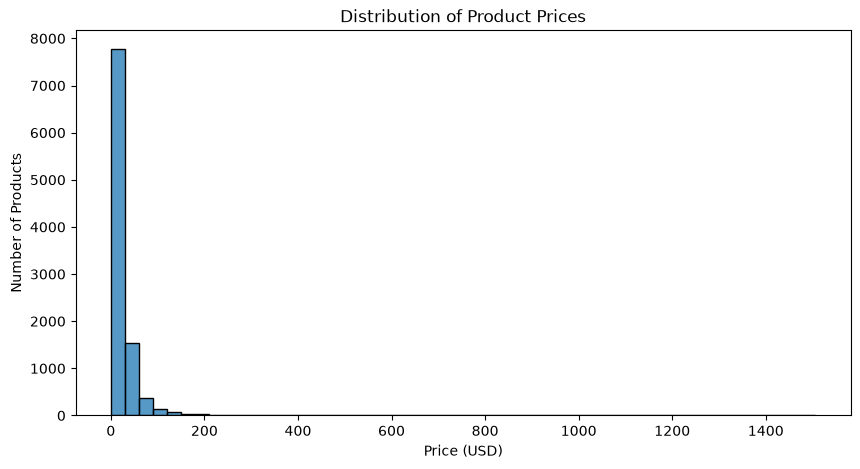

In [12]:

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="price", bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Products")

plt.show()


### Explore numeric relationships

The correlation heatmap summarizes pairwise relationships between numeric columns. Correlation can indicate patterns, but it does not prove causation.

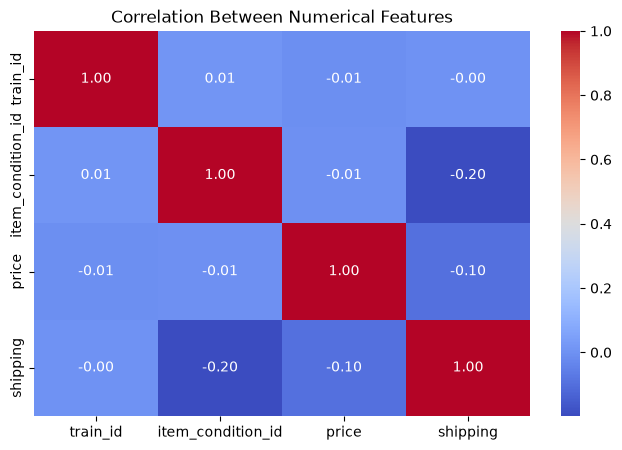

In [13]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 5))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

## 3. Prepare features and train the Ridge regression model

This section builds the main price-prediction pipeline. Product text is converted into TF-IDF features, categories and brands are encoded, and numeric fields are imputed where needed. Ridge regression learns from the processed features. The target price is transformed during training to help handle its skewed distribution.

In [14]:

# Install scikit-learn first if it is not installed:
# %pip install scikit-learn

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import mean_squared_log_error

# Load the sample
df = pd.read_csv("train.tsv", sep="\t", nrows=10000)

# Remove records with invalid target prices
df = df.dropna(subset=["price"])
df = df[df["price"] >= 0].copy()

# Prepare text and categorical features
df["text_features"] = (
    df["name"].fillna("") + " " +
    df["item_description"].fillna("")
)

df["category_name"] = df["category_name"].fillna("Unknown")
df["brand_name"] = df["brand_name"].fillna("Unknown")

# Select input features and target
X = df[
    ["text_features", "category_name", "brand_name",
     "item_condition_id", "shipping"]
]
y = df["price"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert text and categories into numerical features
preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(max_features=15000, min_df=2),
     "text_features"),
    ("category", OneHotEncoder(handle_unknown="ignore"),
     ["category_name"]),
    ("brand", OneHotEncoder(handle_unknown="ignore"),
     ["brand_name"]),
    ("other", SimpleImputer(strategy="most_frequent"),
     ["item_condition_id", "shipping"])
])

# Build the regression pipeline
regression_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", Ridge(alpha=2.0))
])

# Train on log-transformed prices
model = TransformedTargetRegressor(
    regressor=regression_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

model.fit(X_train, y_train)

# Predict prices
y_pred = np.maximum(model.predict(X_test), 0)

# Evaluate the model
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))
print("RMSLE:", round(np.sqrt(
    mean_squared_log_error(y_test, y_pred)
), 4))


MAE: 13.09
RMSE: 32.93
R2 Score: 0.2315
RMSLE: 0.5685


### Save a trained model

This cell saves the model object to a `.pkl` file so it can be loaded later without training it again. The final saved model is also updated in a later cell after tuning.

In [15]:

import joblib

joblib.dump(model, "mercari_price_model.pkl")

print("Model saved successfully!")


Model saved successfully!


### Compare actual and predicted prices

The plot helps visually compare model predictions with the true prices in the test set. Large differences indicate prediction errors.

,Actual Price,Predicted Price
6252,21.0,11.134728
4684,29.0,31.907308
1731,7.0,10.309499
4742,40.0,23.224931
4521,16.0,20.672824
6340,10.0,11.243825
576,19.0,16.498077
5202,10.0,18.480055
6363,6.0,11.377100
439,69.0,39.312244


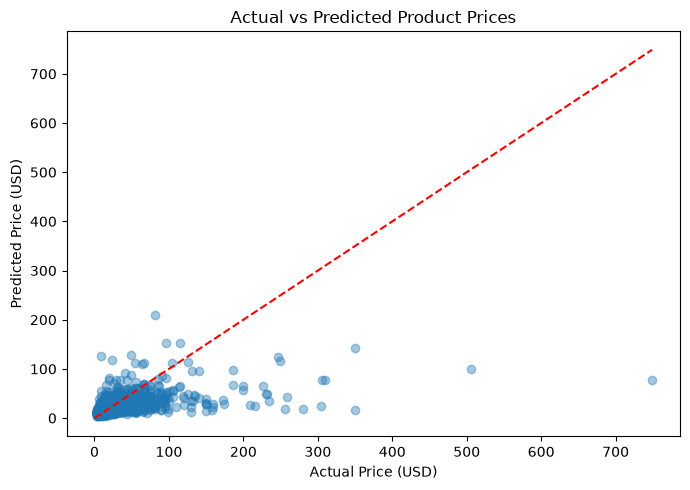

In [16]:

import matplotlib.pyplot as plt
import pandas as pd

# Compare actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

display(results.head(10))

# Actual vs predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.title("Actual vs Predicted Product Prices")

# Reference line
max_price = max(y_test.max(), y_pred.max())
plt.plot([0, max_price], [0, max_price], "r--")

plt.tight_layout()
plt.show()


## 4. Try a Random Forest model

This section trains and evaluates a Random Forest using structured product fields. It provides a comparison with the text-based Ridge model, although the feature sets are not identical.

In [17]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import numpy as np

# Use a manageable subset of features
simple_features = [
    "item_condition_id", "shipping",
    "category_name", "brand_name"
]

X_simple = df[simple_features].copy()
y_simple = df["price"].copy()

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42
)

numeric_features = ["item_condition_id", "shipping"]
categorical_features = ["category_name", "brand_name"]

preprocessor_simple = ColumnTransformer([
    ("num", SimpleImputer(strategy="most_frequent"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant",
                                  fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

rf_model = Pipeline([
    ("preprocessing", preprocessor_simple),
    ("regressor", RandomForestRegressor(
        n_estimators=50, max_depth=15,
        random_state=42, n_jobs=-1
    ))
])

rf_model.fit(X_train_s, y_train_s)
rf_pred = np.maximum(rf_model.predict(X_test_s), 0)

print("Random Forest MAE:",
      round(mean_absolute_error(y_test_s, rf_pred), 2))
print("Random Forest RMSE:",
      round(np.sqrt(mean_squared_error(y_test_s, rf_pred)), 2))
print("Random Forest R2:",
      round(r2_score(y_test_s, rf_pred), 4))


Random Forest MAE: 17.21
Random Forest RMSE: 36.0
Random Forest R2: 0.082


### Additional exploratory plots

These plots revisit price and feature patterns to support interpretation of the dataset before comparing model results.

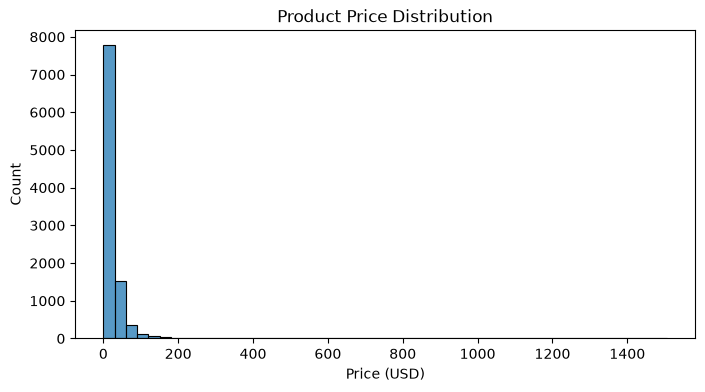

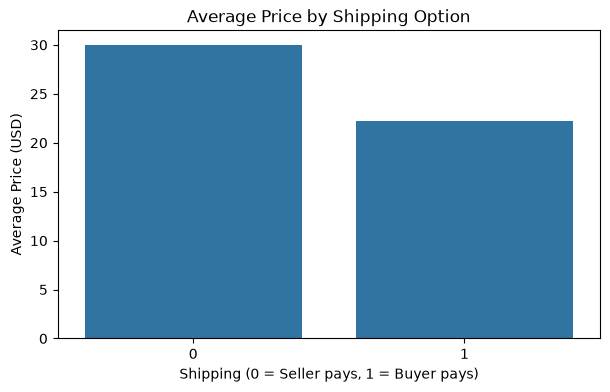

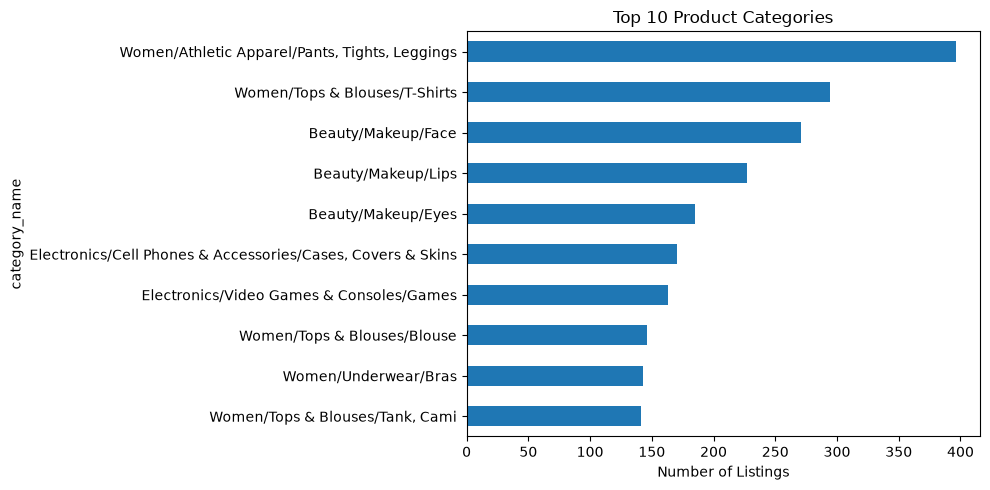

Top 10 brands:


brand_name
Unknown              4261
Nike                  350
PINK                  348
Victoria's Secret     322
LuLaRoe               201
Apple                 111
FOREVER 21            108
Nintendo               99
Michael Kors           87
Sephora                86
Name: count, dtype: int64

In [18]:

# 1. Price distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["price"], bins=50)
plt.title("Product Price Distribution")
plt.xlabel("Price (USD)")
plt.show()

# 2. Average price by shipping option
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="shipping", y="price", errorbar=None)
plt.title("Average Price by Shipping Option")
plt.xlabel("Shipping (0 = Seller pays, 1 = Buyer pays)")
plt.ylabel("Average Price (USD)")
plt.show()

# 3. Top 10 categories by listing count
top_categories = df["category_name"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_categories.sort_values().plot(kind="barh")
plt.title("Top 10 Product Categories")
plt.xlabel("Number of Listings")
plt.tight_layout()
plt.show()

# Most common brands
print("Top 10 brands:")
display(df["brand_name"].value_counts().head(10))


## 5. Tune the Ridge model

This section evaluates different Ridge regularization strengths (`alpha`). The goal is to select a value that reduces validation error rather than relying on an arbitrary setting.

In [19]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Try different Ridge regularization strengths
alpha_values = [0.5, 1.0, 2.0, 5.0, 10.0]
comparison = []

for alpha in alpha_values:
    candidate = clone(model)
    candidate.regressor__regressor__regressor__alpha = alpha

    candidate.fit(X_train, y_train)
    predictions = np.maximum(candidate.predict(X_test), 0)

    comparison.append({
        "Alpha": alpha,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))


,Alpha,MAE,RMSE,R2
0,0.5,13.0852,32.9342,0.2315
1,1.0,13.0852,32.9342,0.2315
2,2.0,13.0852,32.9342,0.2315
3,5.0,13.0852,32.9342,0.2315
4,10.0,13.0852,32.9342,0.2315


### Inspect the available alpha parameter

This cell lists the model parameter paths that end in `alpha`, which helps identify the correct parameter name for tuning the nested pipeline.

In [20]:
[p for p in model.get_params() if p.endswith("alpha")]

['regressor__regressor__alpha']

### Review an initial model comparison

This table summarizes the results recorded for the models in this cell. Use metrics calculated from the current run for the final report; avoid presenting manually entered or outdated scores as current results.

In [21]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Ridge with text features",
        "MAE": 13.0852,
        "RMSE": 32.9342,
        "R2": 0.2315
    },
    {
        "Model": "Random Forest without text features",
        "MAE": 17.21,
        "RMSE": 36.00,
        "R2": 0.0820
    }
])

display(results)
results.to_csv("model_comparison.csv", index=False)

,Model,MAE,RMSE,R2
0,Ridge with text features,13.0852,32.9342,0.2315
1,Random Forest without text features,17.2100,36.0000,0.0820


### Search for the best alpha

The model is evaluated across candidate alpha values, and the value with the best validation performance is selected.

In [22]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]
comparison = []

for alpha in alpha_values:
    candidate = clone(model)

    # Correct Ridge parameter path
    candidate.set_params(regressor__regressor__alpha=alpha)

    candidate.fit(X_train, y_train)
    predictions = np.maximum(candidate.predict(X_test), 0)

    comparison.append({
        "Alpha": alpha,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

# Select the model with the lowest MAE
best_alpha = comparison_df.loc[
    comparison_df["MAE"].idxmin(), "Alpha"
]

print("Best alpha:", best_alpha)


,Alpha,MAE,RMSE,R2
0,0.01,23.8316,60.1216,-1.5610
1,0.10,15.7197,35.5510,0.1045
2,0.50,13.7951,33.2932,0.2147
3,1.00,13.3361,32.9732,0.2297
4,2.00,13.0852,32.9342,0.2315
5,5.00,13.0508,33.3644,0.2113
6,10.00,13.2104,34.0116,0.1804
7,50.00,14.0422,35.8508,0.0894


Best alpha: 5.0


### Fit the tuned model

A copy of the original pipeline is configured with the selected alpha and fitted using the training data.

In [23]:
best_model = clone(model)

best_model.set_params(
    regressor__regressor__alpha=best_alpha
)

best_model.fit(X_train, y_train)

import joblib
joblib.dump(best_model, "mercari_price_model.pkl")

print("Best model saved successfully!")

Best model saved successfully!


### Check the training setup

These printed shapes help confirm how many training examples and target values are being used.

In [24]:
print(model)
print("Training features:", X_train.shape)
print("Target:", y_train.shape)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessing',
                                                      ColumnTransformer(transformers=[('text',
                                                                                       TfidfVectorizer(max_features=15000,
                                                                                                       min_df=2),
                                                                                       'text_features'),
                                                                                      ('category',
                                                                                       OneHotEncoder(handle_unknown='ignore'),
                                                                                       ['category_name']),
                                                                                

### Confirm the tuning result

Review the selected alpha and the fitted model's parameters to confirm that tuning has been applied.

In [25]:
# Confirm the selected alpha
print("Best alpha:", best_alpha)

# Check the tuned model's parameters
print(best_model)

# Evaluate the tuned model on test data
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_best = np.maximum(best_model.predict(X_test), 0)

print("Final Model Results")
print("MAE:", round(mean_absolute_error(y_test, y_pred_best), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_best)), 4))
print("R2 Score:", round(r2_score(y_test, y_pred_best), 4))

# Save the tuned model
import joblib
joblib.dump(best_model, "mercari_price_model.pkl")

print("Tuned model saved successfully!")

Best alpha: 5.0
TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessing',
                                                      ColumnTransformer(transformers=[('text',
                                                                                       TfidfVectorizer(max_features=15000,
                                                                                                       min_df=2),
                                                                                       'text_features'),
                                                                                      ('category',
                                                                                       OneHotEncoder(handle_unknown='ignore'),
                                                                                       ['category_name']),
                                                                

## 6. Evaluate the tuned model

This section calculates prediction metrics and visualizes how the model performs on held-out test data. MAE and RMSE measure error size, while R² indicates how much variation in price the model explains.

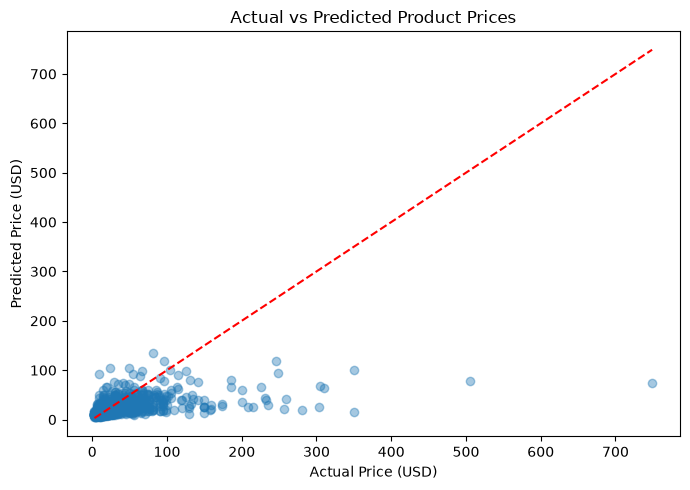

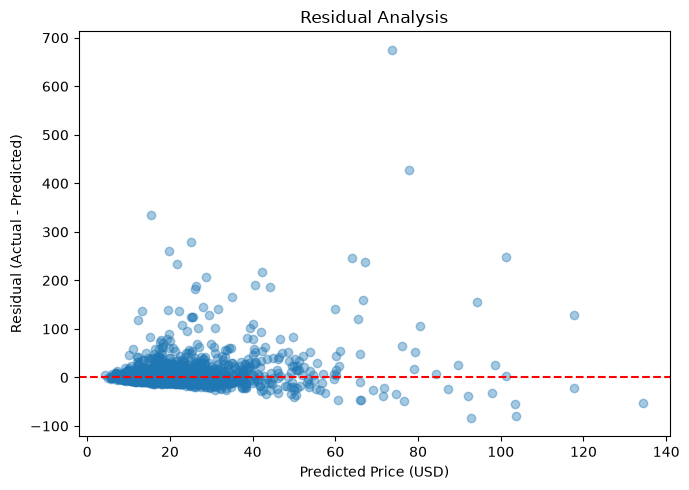

MAE: 13.0508
RMSE: 33.3644
R2: 0.2113


In [26]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict using the saved best model in memory
y_pred = np.maximum(best_model.predict(X_test), 0)

# Calculate residuals
residuals = np.asarray(y_test) - y_pred

# Actual vs predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.4)
limits = [
    min(float(np.min(y_test)), float(np.min(y_pred))),
    max(float(np.max(y_test)), float(np.max(y_pred)))
]
plt.plot(limits, limits, "r--")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.title("Actual vs Predicted Product Prices")
plt.tight_layout()
plt.show()

# Residual plot
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price (USD)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis")
plt.tight_layout()
plt.show()

print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("R2:", round(r2_score(y_test, y_pred), 4))


### Report the evaluation metrics

The metrics are calculated from predictions and the actual test prices. Lower MAE/RMSE generally indicates smaller errors; a higher R² indicates a better fit.

In [27]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def evaluate_model(name, estimator, X_test, y_test):
    predictions = np.maximum(estimator.predict(X_test), 0)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }

results = [
    evaluate_model("Original Ridge", model, X_test, y_test),
    evaluate_model("Tuned Ridge (alpha=5)", best_model, X_test, y_test)
]

results_df = pd.DataFrame(results)
display(results_df.round(4))

results_df.to_csv("model_comparison.csv", index=False)
print("Saved model_comparison.csv")


,Model,MAE,RMSE,R2
0,Original Ridge,13.0852,32.9342,0.2315
1,Tuned Ridge (alpha=5),13.0508,33.3644,0.2113


Saved model_comparison.csv


### Save individual prediction results

This cell puts actual and predicted prices together in a table and exports them for later inspection.

In [28]:

prediction_results = pd.DataFrame({
    "Actual Price": np.asarray(y_test),
    "Predicted Price": y_pred,
    "Residual": residuals
})

display(prediction_results.head(10))
prediction_results.to_csv("prediction_results.csv", index=False)

print("Saved prediction_results.csv")


,Actual Price,Predicted Price,Residual
0,21.0,10.389661,10.610339
1,29.0,26.217601,2.782399
2,7.0,10.627331,-3.627331
3,40.0,22.489814,17.510186
4,16.0,23.018966,-7.018966
5,10.0,12.499701,-2.499701
6,19.0,16.579950,2.420050
7,10.0,18.386594,-8.386594
8,6.0,11.042621,-5.042621
9,69.0,39.001325,29.998675


Saved prediction_results.csv


## 7. SHAP model explanations

SHAP estimates how features contribute to model predictions. The package-install cell prepares the environment; the following explanation cell should be run and checked for errors before claiming SHAP analysis is complete.

In [29]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


### Explain feature contributions with SHAP

This cell transforms a sample through the fitted preprocessing pipeline and calculates SHAP values to show which features influence the selected predictions. If it raises an error, keep the error visible for troubleshooting rather than treating the explanation as completed.

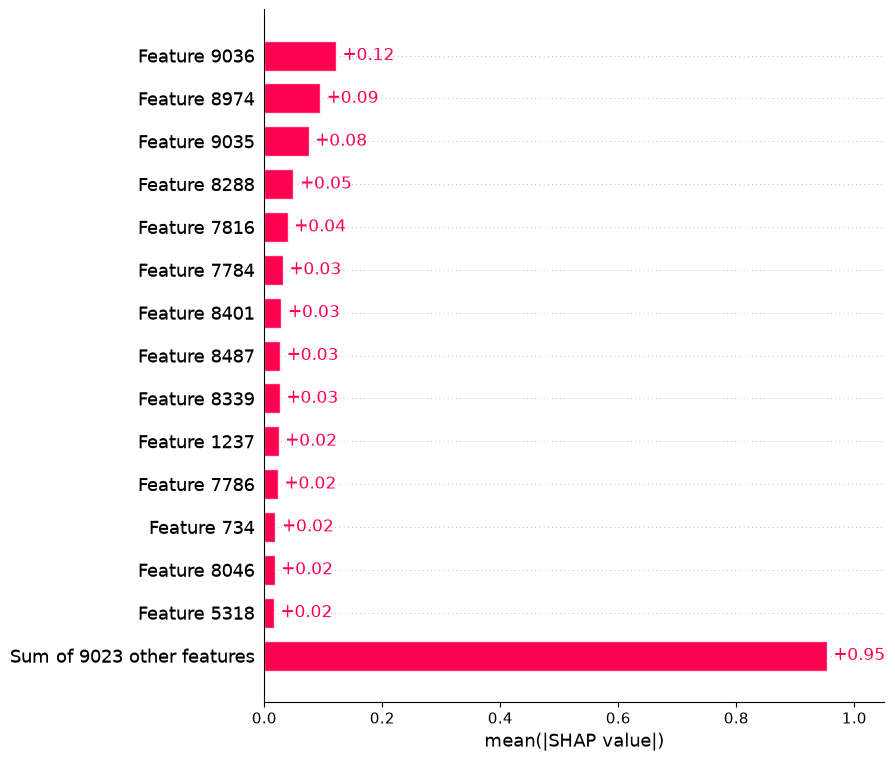

In [30]:
import shap
import numpy as np

# Transform the input using the fitted preprocessing pipeline
preprocessor = best_model.regressor_.named_steps["preprocessing"]

X_explain = X_test.head(20)
X_transformed = preprocessor.transform(X_explain)

# Explain the Ridge estimator using the transformed features
ridge = best_model.regressor_.named_steps["regressor"]

explainer = shap.LinearExplainer(ridge, X_transformed)
shap_values = explainer(X_transformed)

shap.plots.bar(shap_values, max_display=15)

## 8. Track the experiment with MLflow

MLflow records the experiment's parameters, evaluation metrics, and model artifact, making it easier to track how the model was trained and evaluated.

In [31]:
%pip install mlflow

Note: you may need to restart the kernel to use updated packages.


### Log model details and metrics

This cell records the run information in MLflow. Ensure the logged parameters and metrics match the final model and the predictions being evaluated.

In [32]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = np.maximum(best_model.predict(X_test), 0)

with mlflow.start_run(run_name="Mercari_Ridge_Alpha_5"):
    mlflow.log_param("model", "Ridge Regression")
    mlflow.log_param("alpha", 5.0)
    mlflow.log_param("training_rows", len(X_train))
    mlflow.log_param("test_rows", len(X_test))

    mlflow.log_metric(
        "MAE", mean_absolute_error(y_test, y_pred)
    )
    mlflow.log_metric(
        "RMSE", np.sqrt(mean_squared_error(y_test, y_pred))
    )
    mlflow.log_metric(
        "R2", r2_score(y_test, y_pred)
    )

    mlflow.sklearn.log_model(
    best_model,
    name="mercari_ridge_model",
    skops_trusted_types=["numpy.dtype"]
)

print("Experiment logged to MLflow.")

Experiment logged to MLflow.


## 9. Cross-validation

Cross-validation evaluates the model across multiple training/validation splits. The average score gives a more stable view of performance than relying on one split alone.

In [33]:
from sklearn.model_selection import cross_val_score
import numpy as np

cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

cv_mae = -cv_scores

print("Cross-validation MAE:", cv_mae)
print("Average CV MAE:", cv_mae.mean())
print("Standard deviation:", cv_mae.std())

Cross-validation MAE: [13.13806435 12.19835017 11.59608684 13.0207545  13.02644802]
Average CV MAE: 12.595940774659997
Standard deviation: 0.6029075119797592


### Summarize final metrics

This section organizes the evaluation metrics into a table so the model's test-set performance can be reviewed consistently.

In [34]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_squared_log_error
)
import pandas as pd
import numpy as np

def evaluate_model(name, model, X_test, y_test):
    predictions = np.maximum(model.predict(X_test), 0)

    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions),
        "RMSLE": np.sqrt(
            mean_squared_log_error(y_test, predictions)
        )
    }

comparison = pd.DataFrame([
    evaluate_model("Tuned Ridge", best_model, X_test, y_test)
])

display(comparison)

,Model,MAE,RMSE,R2,RMSLE
0,Tuned Ridge,13.05084,33.36437,0.211309,0.567067


## 10. Compare a voting ensemble

This section combines predictions from tree-based models by averaging them. An ensemble is not automatically better; use the test-set metrics to decide whether it improves on the tuned Ridge model.

In [35]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Define the structured features used by this ensemble
structured_columns = [
    "item_condition_id",
    "shipping",
    "category_name",
    "brand_name"
]

extra_trees_model = Pipeline([
    ("preprocessing", rf_model.named_steps["preprocessing"]),
    ("regressor", ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_model.fit(
    X_train[structured_columns],
    y_train
)

rf_predictions = np.maximum(
    rf_model.predict(X_test[structured_columns]), 0
)

et_predictions = np.maximum(
    extra_trees_model.predict(X_test[structured_columns]), 0
)

voting_predictions = (rf_predictions + et_predictions) / 2

print("Voting Ensemble MAE:",
      mean_absolute_error(y_test, voting_predictions))

print("Voting Ensemble RMSE:",
      np.sqrt(mean_squared_error(y_test, voting_predictions)))

print("Voting Ensemble R2:",
      r2_score(y_test, voting_predictions))

Voting Ensemble MAE: 15.851380005194585
Voting Ensemble RMSE: 35.28691464144919
Voting Ensemble R2: 0.11779738551815377


## 11. Plot prediction performance

This cell creates predictions from the tuned Ridge model for further visual evaluation. The predictions are constrained to non-negative prices.

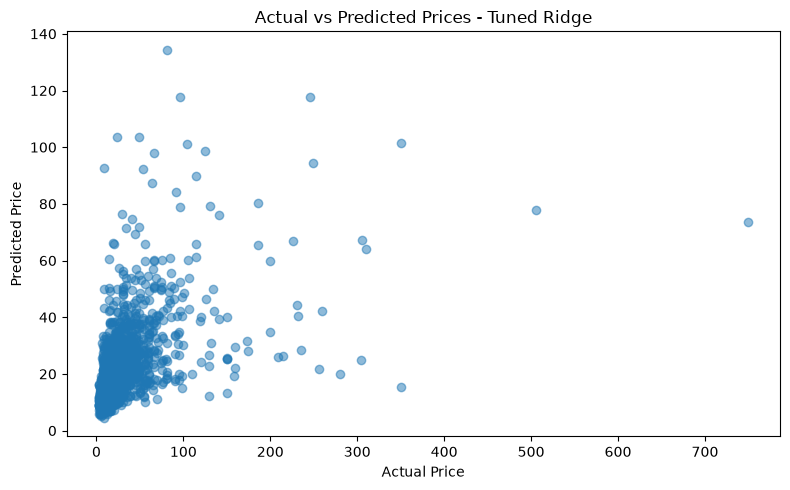

In [36]:
import matplotlib.pyplot as plt

ridge_predictions = np.maximum(
    best_model.predict(X_test), 0
)

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    ridge_predictions,
    alpha=0.5
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices - Tuned Ridge")

plt.tight_layout()
plt.show()

### Inspect residuals

A residual is the actual price minus the predicted price. The residual plot helps reveal systematic errors, outliers, and whether error size changes with predicted price.

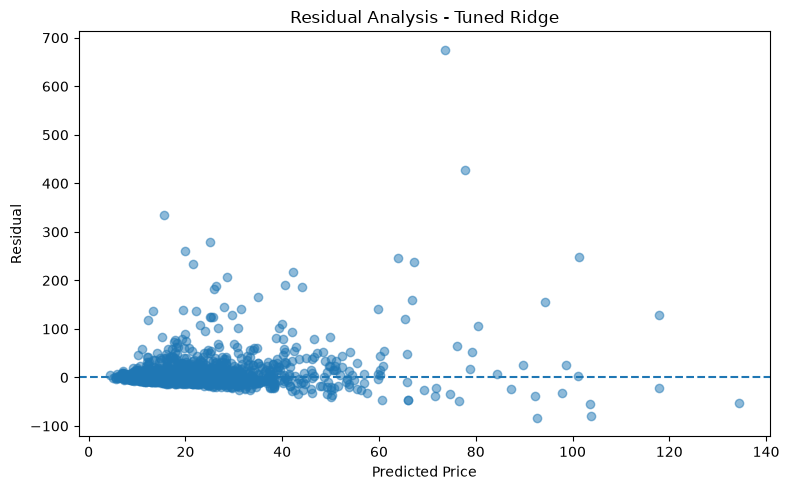

In [37]:
residuals = y_test - ridge_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    ridge_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Analysis - Tuned Ridge")

plt.tight_layout()
plt.show()

## 12. Save the final model and metrics

This cell saves the selected model and writes its computed evaluation metrics to a JSON file for use in the application and final report.

In [38]:
import joblib
import json

joblib.dump(best_model, "mercari_price_model.pkl")

final_metrics = {
    "MAE": float(
        mean_absolute_error(y_test, ridge_predictions)
    ),
    "RMSE": float(
        np.sqrt(mean_squared_error(y_test, ridge_predictions))
    ),
    "R2": float(
        r2_score(y_test, ridge_predictions)
    ),
    "RMSLE": float(
        np.sqrt(mean_squared_log_error(
            y_test, ridge_predictions
        ))
    ),
    "Cross_Validation_MAE": float(cv_mae.mean())
}

with open("final_metrics.json", "w") as file:
    json.dump(final_metrics, file, indent=4)

print("Final Ridge model saved successfully.")
print(final_metrics)

Final Ridge model saved successfully.
{'MAE': 13.050840489497405, 'RMSE': 33.364369547932284, 'R2': 0.21130913179828914, 'RMSLE': 0.5670666702487708, 'Cross_Validation_MAE': 12.595940774659997}


### Verify the saved model

The saved model is loaded back from disk and used to make sample predictions. This checks that the model artifact can be reused after training.

In [39]:
import joblib
import numpy as np

loaded_model = joblib.load("mercari_price_model.pkl")

test_predictions = np.maximum(
    loaded_model.predict(X_test),
    0
)

print("Model loaded successfully.")
print("Sample actual prices:", y_test.iloc[:5].tolist())
print("Sample predicted prices:", test_predictions[:5].tolist())

Model loaded successfully.
Sample actual prices: [21.0, 29.0, 7.0, 40.0, 16.0]
Sample predicted prices: [10.389661143260247, 26.217600811868937, 10.627331384491141, 22.4898136676415, 23.01896588866059]


### Export batch predictions

This cell exports the test examples with actual and predicted prices to a CSV file for further analysis or review.

In [40]:
batch_results = X_test.copy()

batch_results["Actual_Price"] = y_test.values
batch_results["Predicted_Price"] = test_predictions

batch_results.to_csv("prediction_results.csv", index=False)

print("Batch predictions saved successfully.")
display(batch_results.head())

Batch predictions saved successfully.


,text_features,category_name,brand_name,item_condition_id,shipping,Actual_Price,Predicted_Price
6252,N64 super mario 64 (label stain) Great item gr...,Electronics/Video Games & Consoles/Games,Unknown,3,1,21.0,10.389661
4684,Jordan 9c Retro Gamma 11s Size 9c Gamma gamma ...,Kids/Boys 2T-5T/Shoes,Nike,3,0,29.0,26.217601
1731,5 Pair of Lashes + Lash Tweezers Perfect for t...,Beauty/Makeup/Eyes,Unknown,1,1,7.0,10.627331
4742,Bundle for LizKay GB Girls size 10. Fits like ...,Kids/Girls (4+)/Swimwear,Unknown,2,0,40.0,22.489814
4521,New Balance Minimus size 8 - women Good used c...,Women/Shoes/Athletic,New Balance,3,0,16.0,23.018966


## 13. Compare the evaluated models

The comparison table places the selected Ridge model, Random Forest, and voting ensemble side by side using the same test target. Choose the final model based on measured performance, not on model complexity.

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Tuned Ridge",
        "MAE": mean_absolute_error(y_test, ridge_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, ridge_predictions)),
        "R2": r2_score(y_test, ridge_predictions)
    },
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_test, rf_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, rf_predictions)),
        "R2": r2_score(y_test, rf_predictions)
    },
    {
        "Model": "Voting Ensemble",
        "MAE": mean_absolute_error(y_test, voting_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, voting_predictions)),
        "R2": r2_score(y_test, voting_predictions)
    }
])

display(model_comparison)

,Model,MAE,RMSE,R2
0,Tuned Ridge,13.050840,33.364370,0.211309
1,Random Forest,17.210741,35.995941,0.081989
2,Voting Ensemble,15.851380,35.286915,0.117797


### Save the comparison table

The model comparison is saved as a CSV file so the results can be included in the report.

In [42]:
model_comparison.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully.")

Model comparison saved successfully.


## 14. Check the output folder

This cell displays the notebook's current working directory and lists its files. Use it to locate the saved model, metrics, and prediction CSVs.

In [43]:
import os

print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: C:\Users\Zaish\Desktop\project_merci
['.ipynb_checkpoints', 'app.py', 'batch_predictions.csv', 'final_metrics.json', 'mercari_price_model.pkl', 'Mercari_Price_Prediction.ipynb', 'Mercari_Product_Price_Prediction_Final (1).ipynb', 'Mercari_Product_Price_Prediction_Final (2).ipynb', 'mlflow.db', 'mlruns', 'models', 'model_comparison.csv', 'model_version.txt', 'prediction_results.csv', 'train.tsv']
